In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
from collections import defaultdict

random.seed(42)
np.random.seed(42)

In [3]:
cards = [1,2,3,4,5,6,7,8,9,10,10,10,10]

def draw_card():
    return random.choice(cards)

def usable_ace(hand):
    return 1 in hand and sum(hand)+10 <= 21

def sum_hand(hand):
    return sum(hand)+10 if usable_ace(hand) else sum(hand)

def is_bust(hand):
    return sum_hand(hand) > 21

def score(hand):
    return 0 if is_bust(hand) else sum_hand(hand)

def dealer_policy(hand):
    while sum_hand(hand) < 17:
        hand.append(draw_card())
    return hand

In [4]:
def generate_episode(policy, exploring=False):
    player = [draw_card(), draw_card()]
    dealer = [draw_card(), draw_card()]
    episode = []

    while True:
        state = (sum_hand(player), dealer[0], usable_ace(player))

        if exploring and len(episode)==0:
            action = random.choice([0,1])
        else:
            if callable(policy):
                action = policy(state)
            else:
                action = policy[state]

        episode.append((state, action))

        if action == 1:
            player.append(draw_card())
            if is_bust(player):
                return episode, -1
        else:
            break

    dealer = dealer_policy(dealer)

    if is_bust(dealer) or score(player) > score(dealer):
        return episode, 1
    elif score(player) == score(dealer):
        return episode, 0
    else:
        return episode, -1

In [5]:
def policy_A(s): return 0 if s[0] >= 20 else 1
def policy_B(s): return 0 if s[0] >= 18 else 1
def policy_C(s): return 0 if s[0] >= 17 else 1
def policy_D(s): return random.choice([0,1])

In [8]:
def mc_prediction(policy, episodes):
    V = defaultdict(float)
    N = defaultdict(int)

    for _ in range(episodes):
        episode, reward = generate_episode(policy)
        visited = set()

        for state,_ in episode:
            if state not in visited:
                visited.add(state)
                N[state] += 1
                V[state] += (reward - V[state]) / N[state]
    return V

In [9]:
def mc_es(episodes):
    Q = defaultdict(lambda: np.zeros(2))
    N = defaultdict(int)
    policy = defaultdict(lambda: random.choice([0,1]))

    for _ in range(episodes):
        episode, reward = generate_episode(policy, exploring=True)

        G = 0
        visited = set()

        for s,a in reversed(episode):
            G = reward + G
            if (s,a) not in visited:
                visited.add((s,a))
                N[(s,a)] += 1
                Q[s][a] += (G - Q[s][a]) / N[(s,a)]
                policy[s] = np.argmax(Q[s])

    return Q, policy

In [10]:
def epsilon_greedy(Q, state, eps):
    if random.random() < eps:
        return random.choice([0,1])
    return np.argmax(Q[state])

def mc_epsilon(episodes, eps=0.1):
    Q = defaultdict(lambda: np.zeros(2))
    N = defaultdict(int)

    for _ in range(episodes):
        player = [draw_card(), draw_card()]
        dealer = [draw_card(), draw_card()]
        episode = []

        while True:
            state = (sum_hand(player), dealer[0], usable_ace(player))
            action = epsilon_greedy(Q, state, eps)
            episode.append((state, action))

            if action == 1:
                player.append(draw_card())
                if is_bust(player):
                    reward = -1
                    break
            else:
                break

        dealer = dealer_policy(dealer)

        if is_bust(dealer) or score(player) > score(dealer):
            reward = 1
        elif score(player) == score(dealer):
            reward = 0
        else:
            reward = -1

        G = 0
        visited = set()

        for s,a in reversed(episode):
            G = reward + G
            if (s,a) not in visited:
                visited.add((s,a))
                N[(s,a)] += 1
                Q[s][a] += (G - Q[s][a]) / N[(s,a)]

    return Q

In [11]:
def off_policy_weighted(episodes):
    V = defaultdict(float)
    C = defaultdict(float)

    for _ in range(episodes):
        episode=[]
        player=[draw_card(),draw_card()]
        dealer=[draw_card(),draw_card()]

        while True:
            s=(sum_hand(player),dealer[0],usable_ace(player))
            a=random.choice([0,1])
            episode.append((s,a))

            if a==1:
                player.append(draw_card())
                if is_bust(player):
                    reward=-1; break
            else:
                break

        dealer=dealer_policy(dealer)
        if is_bust(dealer) or score(player)>score(dealer): reward=1
        elif score(player)==score(dealer): reward=0
        else: reward=-1

        G=reward; W=1

        for s,a in reversed(episode):
            C[s]+=W
            V[s]+= (W/C[s])*(G-V[s])
            if a!=policy_A(s): break
            W*=2
    return V

In [12]:
def plot_value(V,title, filename):
    usable=np.zeros((10,10))
    no_usable=np.zeros((10,10))

    for (p,d,a),v in V.items():
        if 12<=p<=21:
            if a: usable[p-12,d-1]=v
            else: no_usable[p-12,d-1]=v

    fig,ax=plt.subplots(1,2, figsize=(14,6))

    im0 = ax[0].imshow(usable, origin='lower')
    ax[0].set_title("Usable Ace")
    ax[0].set_xlabel("Dealer Showing")
    ax[0].set_ylabel("Player Sum")

    im1 = ax[1].imshow(no_usable, origin='lower')
    ax[1].set_title("No Usable Ace")
    ax[1].set_xlabel("Dealer Showing")
    ax[1].set_ylabel("Player Sum")

    dealer_range = np.arange(1, 11)
    player_range = np.arange(12, 22)

    ax[0].set_xticks(np.arange(10))
    ax[0].set_xticklabels(dealer_range)
    ax[0].set_yticks(np.arange(10))
    ax[0].set_yticklabels(player_range)
    
    ax[1].set_xticks(np.arange(10))
    ax[1].set_xticklabels(dealer_range)
    ax[1].set_yticks(np.arange(10))
    ax[1].set_yticklabels(player_range)

    fig.colorbar(im0, ax=ax[0])
    fig.colorbar(im1, ax=ax[1])

    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()



In [13]:

def plot_policy(policy, filename, title):
    usable = np.zeros((10,10))
    no_usable = np.zeros((10,10))

    for (p,d,a), action in policy.items():
        if 12 <= p <= 21:
            if a:
                usable[p-12, d-1] = action
            else:
                no_usable[p-12, d-1] = action

    fig,ax=plt.subplots(1,2, figsize=(14,6))

    im0 = ax[0].imshow(usable, origin='lower')
    ax[0].set_title("Usable Ace")
    ax[0].set_xlabel("Dealer Showing")
    ax[0].set_ylabel("Player Sum")

    im1 = ax[1].imshow(no_usable, origin='lower')
    ax[1].set_title("No Usable Ace")
    ax[1].set_xlabel("Dealer Showing")
    ax[1].set_ylabel("Player Sum")

    dealer_range = np.arange(1, 11)
    player_range = np.arange(12, 22)
    
    ax[0].set_xticks(np.arange(10))
    ax[0].set_xticklabels(dealer_range)
    ax[0].set_yticks(np.arange(10))
    ax[0].set_yticklabels(player_range)
    
    ax[1].set_xticks(np.arange(10))
    ax[1].set_xticklabels(dealer_range)
    ax[1].set_yticks(np.arange(10))
    ax[1].set_yticklabels(player_range)

    fig.colorbar(im0, ax=ax[0])
    fig.colorbar(im1, ax=ax[1])

    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()


In [14]:


def plot_policy_values(Q, filename, title):
    usable = np.zeros((10,10))
    no_usable = np.zeros((10,10))

    for (p,d,a), q in Q.items():
        if 12 <= p <= 21:
            v = np.max(q)
            if a:
                usable[p-12, d-1] = v
            else:
                no_usable[p-12, d-1] = v

    fig,ax=plt.subplots(1,2, figsize=(14,6))

    im0 = ax[0].imshow(usable, origin='lower')
    ax[0].set_title("Usable Ace Value")
    ax[0].set_xlabel("Dealer Showing")
    ax[0].set_ylabel("Player Sum")
    
    im1 = ax[1].imshow(no_usable, origin='lower')
    ax[1].set_title("No Usable Ace Value")
    ax[1].set_xlabel("Dealer Showing")
    ax[1].set_ylabel("Player Sum")

    dealer_range = np.arange(1, 11)
    player_range = np.arange(12, 22)
    
    ax[0].set_xticks(np.arange(10))
    ax[0].set_xticklabels(dealer_range)
    ax[0].set_yticks(np.arange(10))
    ax[0].set_yticklabels(player_range)
    
    ax[1].set_xticks(np.arange(10))
    ax[1].set_xticklabels(dealer_range)
    ax[1].set_yticks(np.arange(10))
    ax[1].set_yticklabels(player_range)

    fig.colorbar(im0, ax=ax[0])
    fig.colorbar(im1, ax=ax[1])

    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()



In [15]:
def evaluate_policy(policy, episodes=200000):
    total = 0
    for _ in range(episodes):
        _, reward = generate_episode(policy)
        total += reward
    return total / episodes

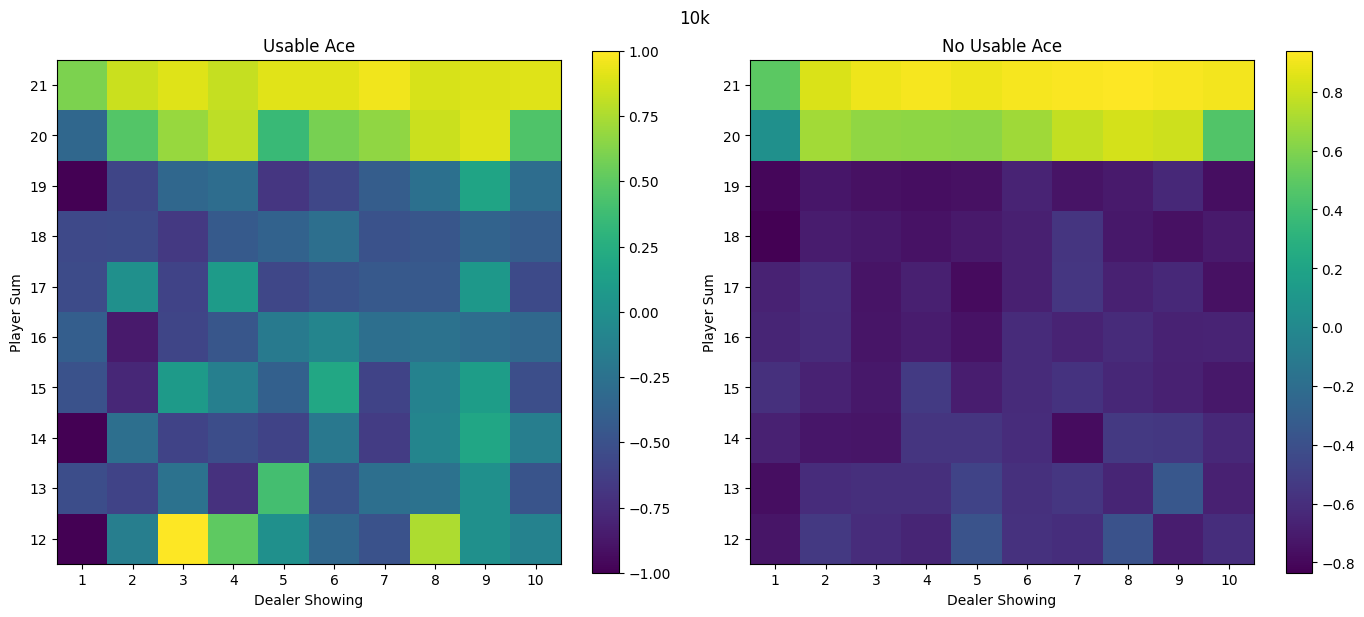

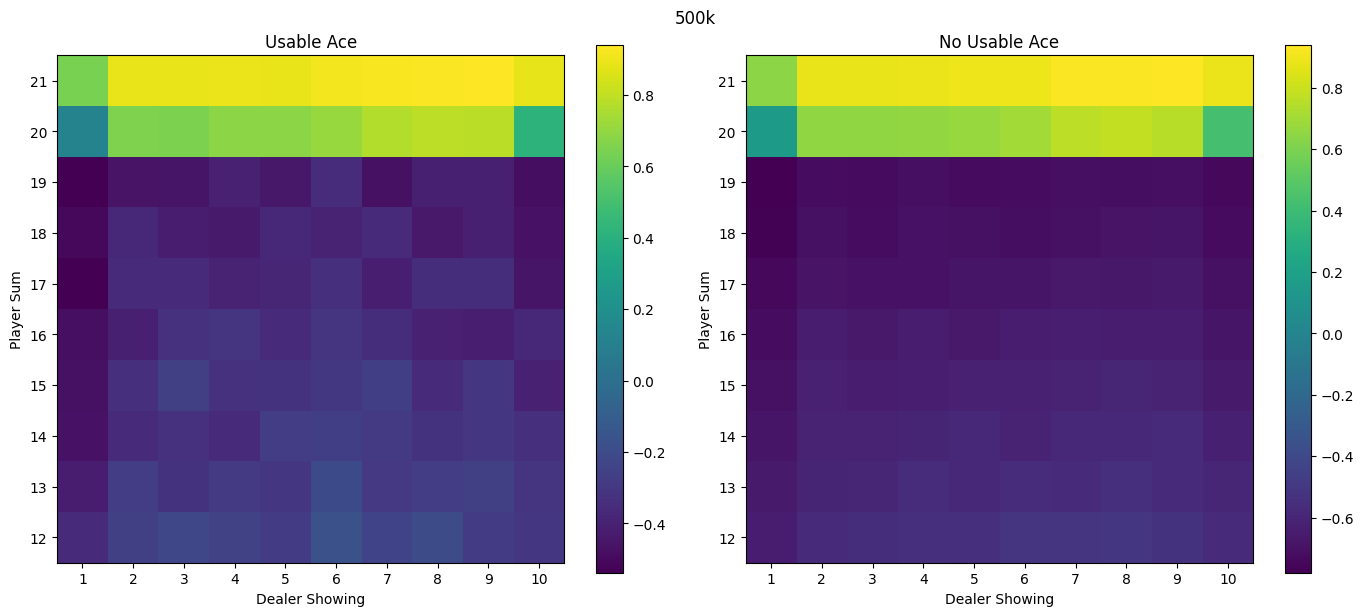

In [16]:
V10 = mc_prediction(policy_A,10000)
plot_value(V10,"10k","value_10k.png")

V500 = mc_prediction(policy_A,500000)
plot_value(V500,"500k","value_500k.png")

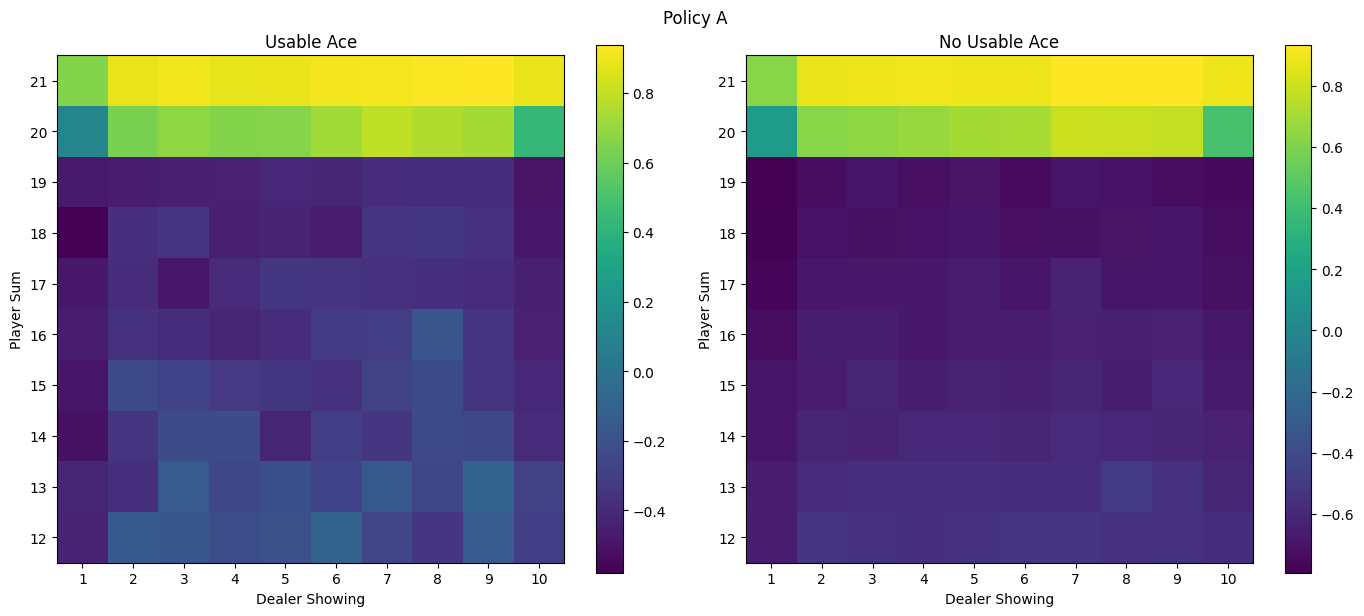

Policy A: Average Reward per Episode = -0.3537


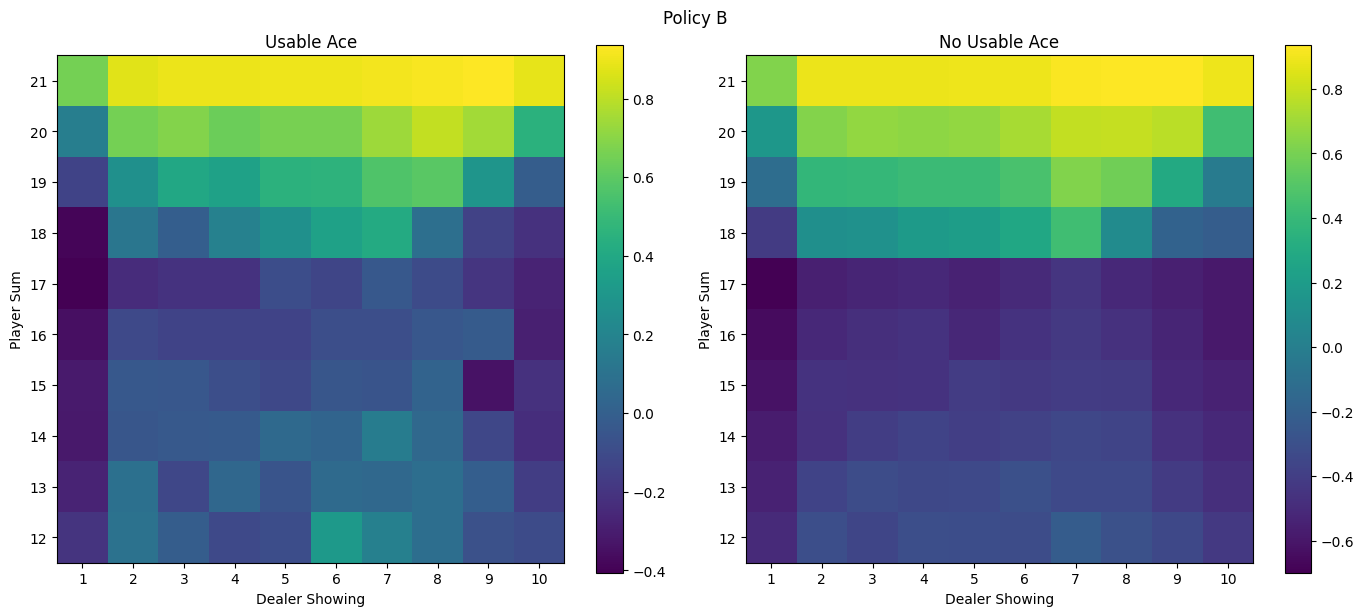

Policy B: Average Reward per Episode = -0.1132


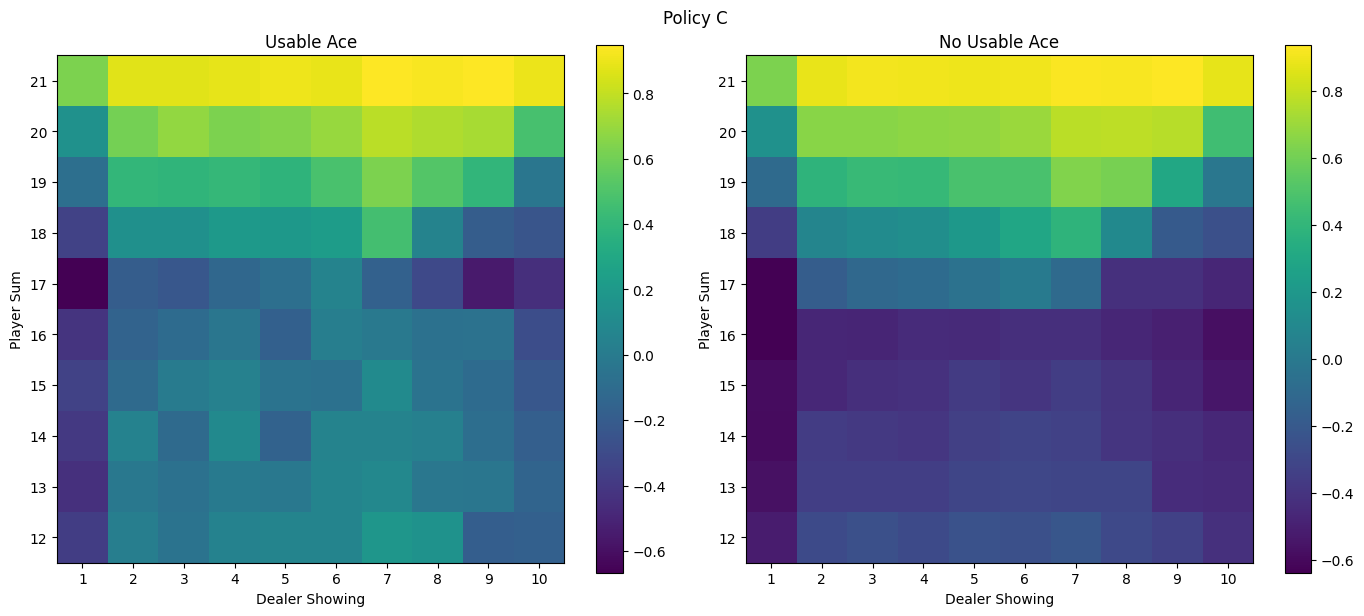

Policy C: Average Reward per Episode = -0.0801


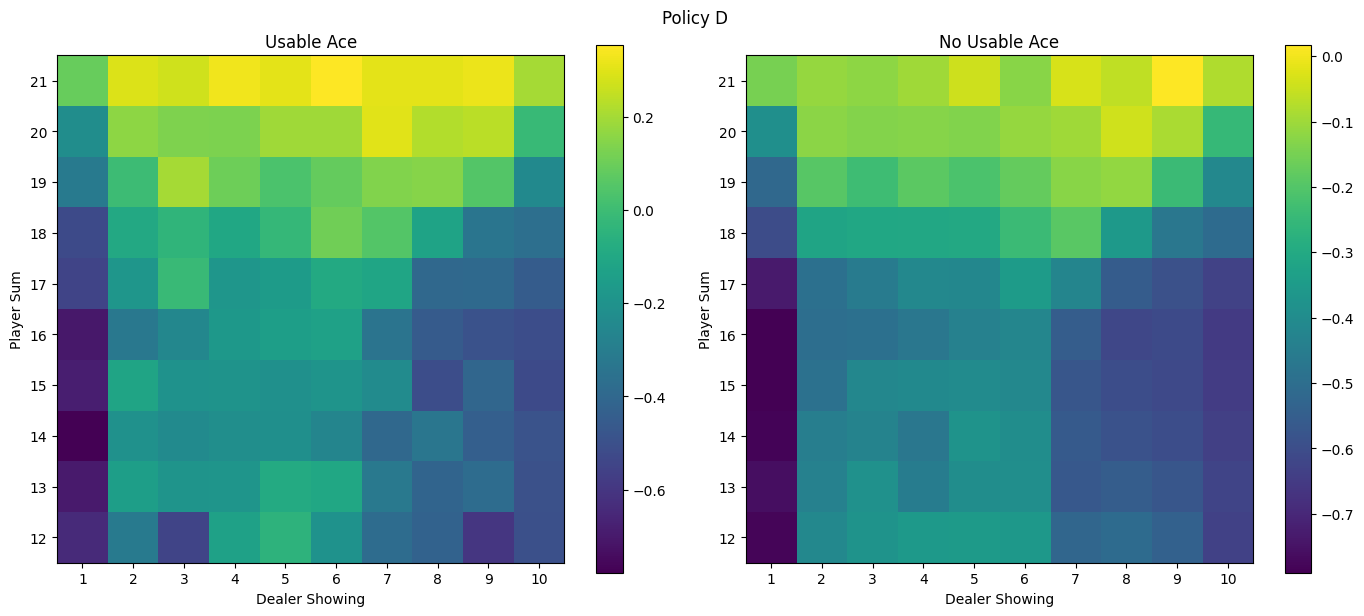

Policy D: Average Reward per Episode = -0.3949


In [17]:
results = {}
for p,name in zip([policy_A,policy_B,policy_C,policy_D],
                  ["A","B","C","D"]):
    V = mc_prediction(p,200000)
    avg = evaluate_policy(p, 200000)
    results[name] = avg

    plot_value(V, f"Policy {name}", f"value_policy_{name}.png")

    print(f"Policy {name}: Average Reward per Episode = {avg:.4f}")

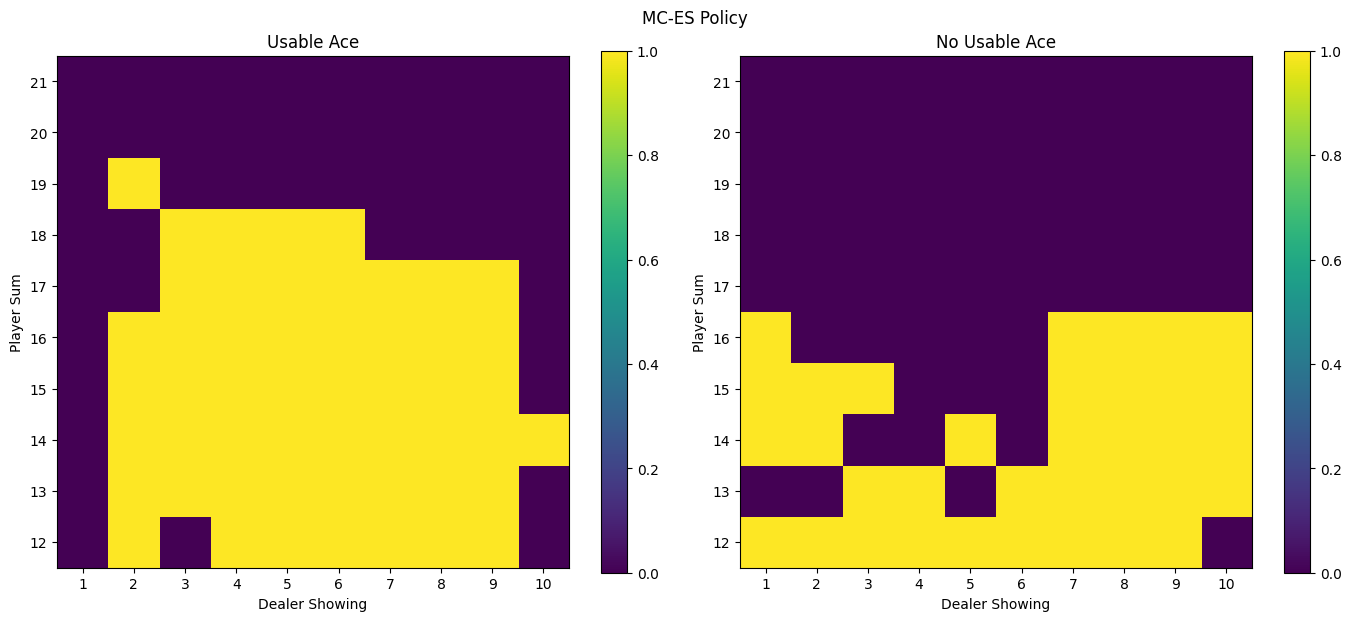

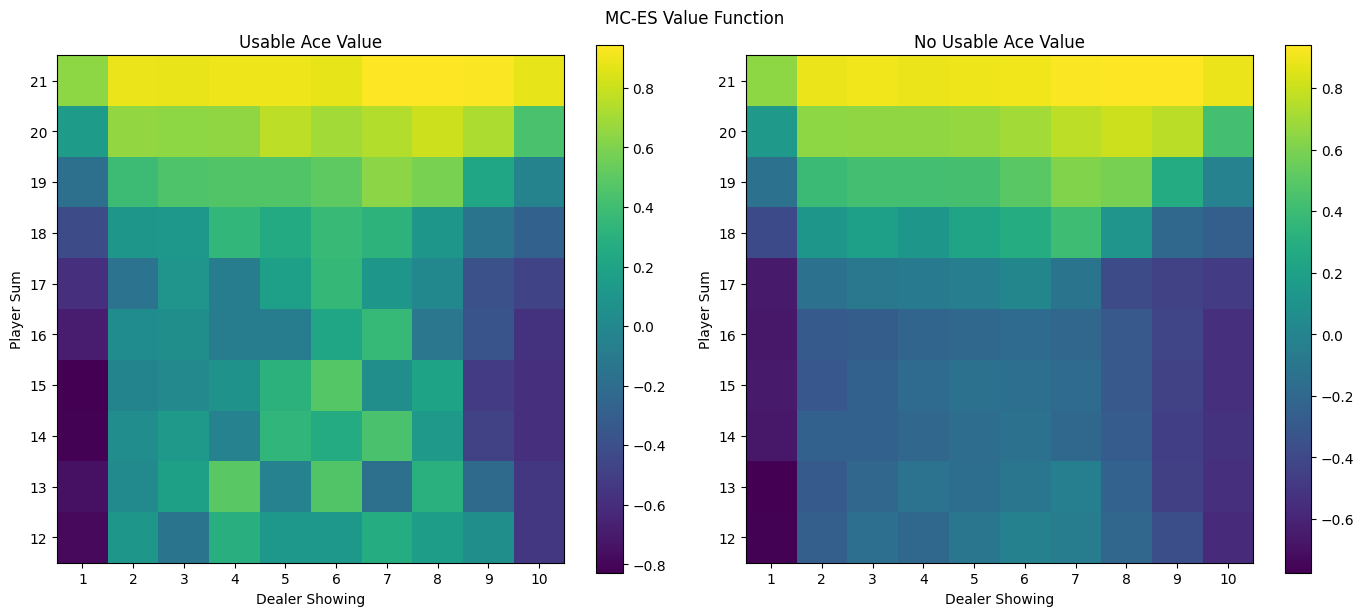

In [18]:
Q_es,pi_es=mc_es(500000)
plot_policy(pi_es, "policy_mc_es.png", "MC-ES Policy")
plot_policy_values(Q_es, "value_mc_es.png", "MC-ES Value Function")

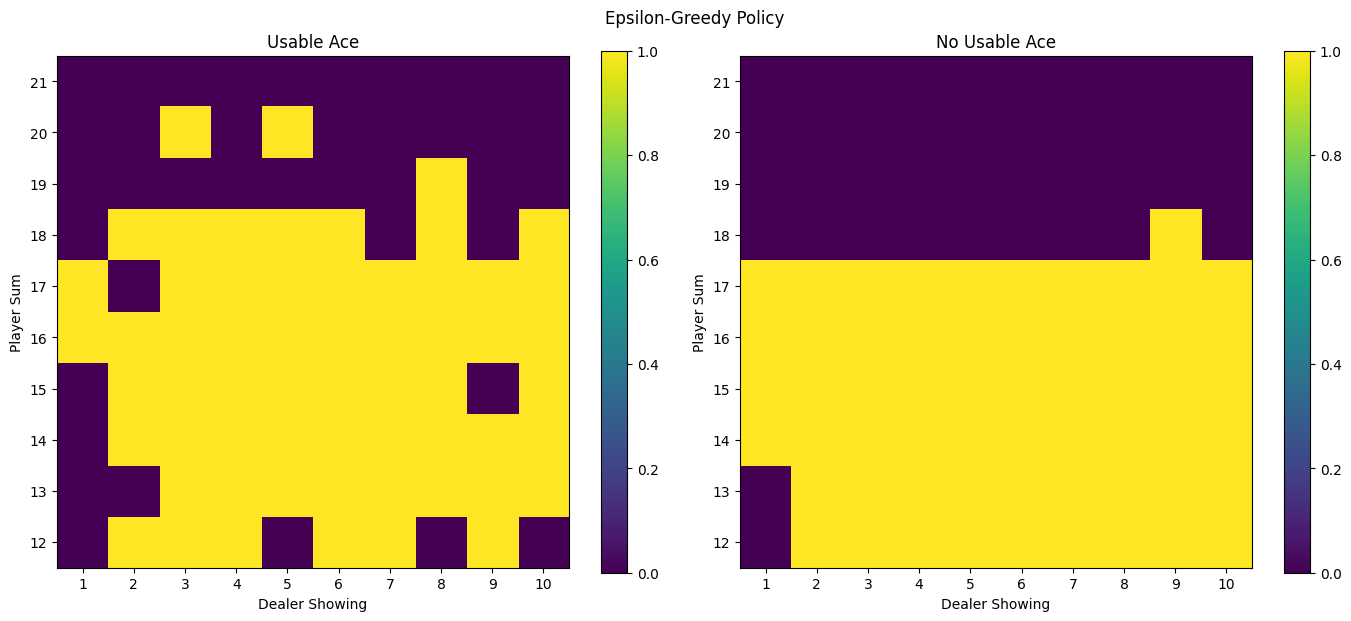

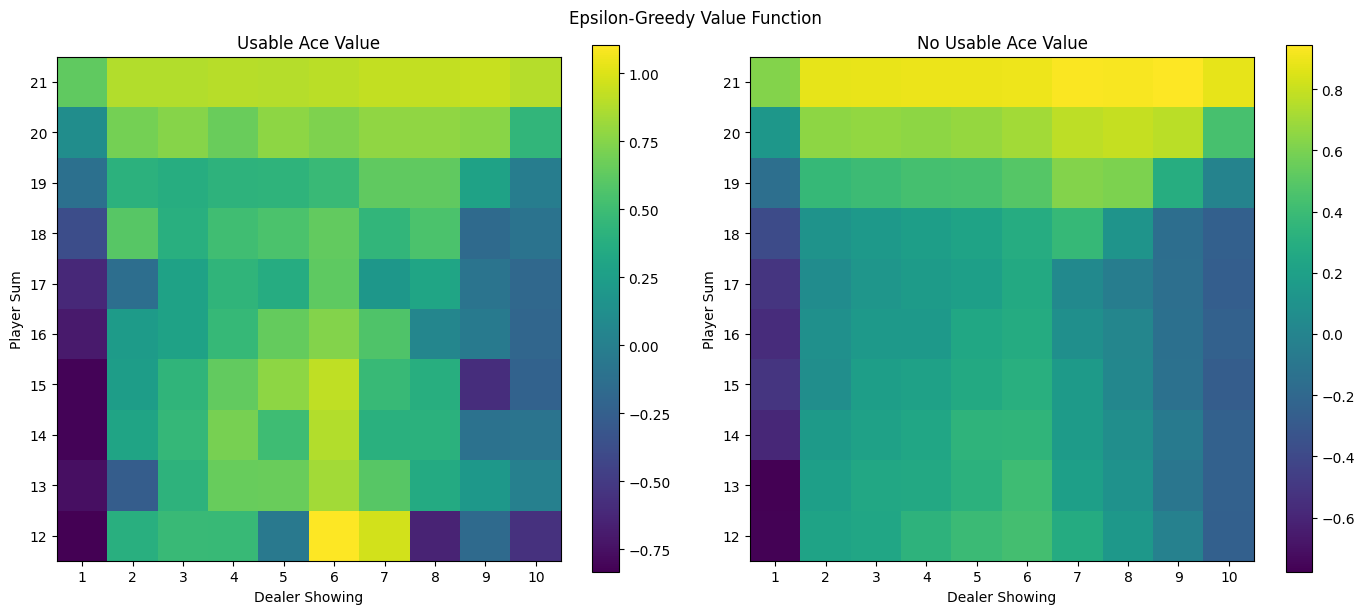

In [19]:
Q_eps=mc_epsilon(500000)
policy_eps = {s: np.argmax(a) for s,a in Q_eps.items()}
plot_policy(policy_eps, "policy_eps.png", "Epsilon-Greedy Policy")
plot_policy_values(Q_eps, "value_eps.png", "Epsilon-Greedy Value Function")

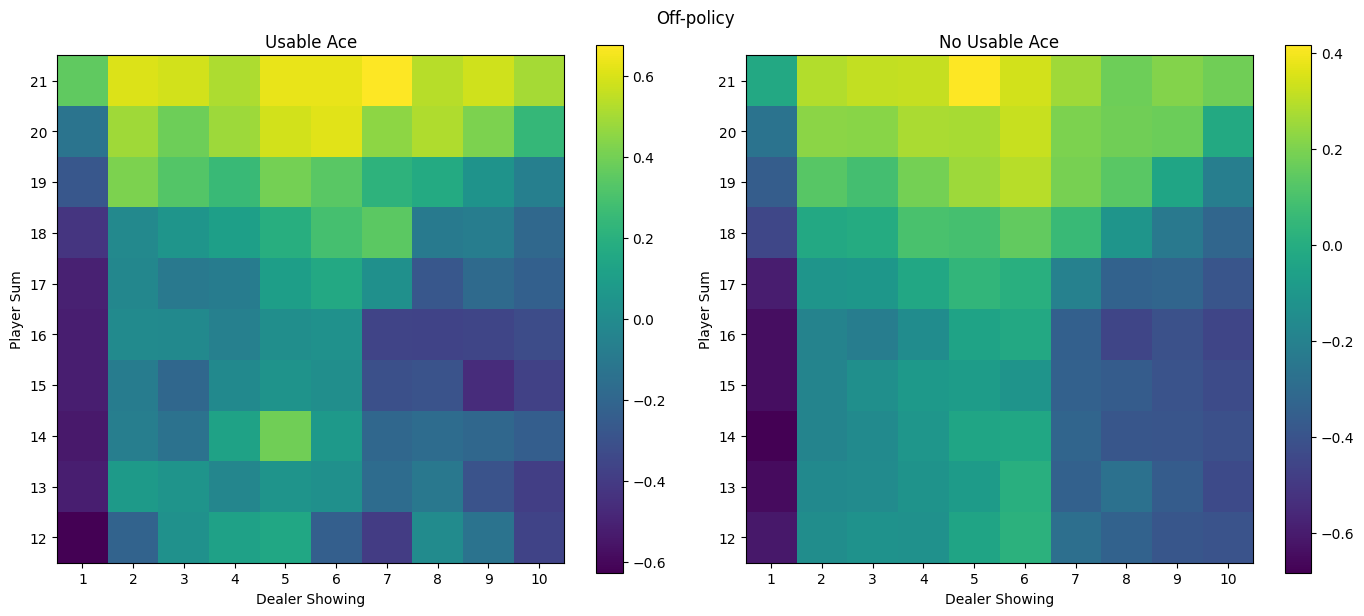

In [20]:
V_off=off_policy_weighted(200000)
plot_value(V_off,"Off-policy","off_policy.png")